# Dynamic Mixed-Precision and Recomputation Policies for needle

**10-714 Deep Learning Systems: final project report**

**Team:** Han Zhang (hanz5), Xia Chu(xiachu)

**Code:** [download the project code (Google Drive, private link)](https://drive.google.com/file/d/REPLACE_WITH_FILE_ID/view?usp=sharing). The archive holds our extended needle library, the experiment scripts, the training logs of every run reported below, and the tests. Section 7 describes its layout.

**Abstract.** Mixed precision and gradient checkpointing both reduce the activation memory of training, with opposite effects on speed and accuracy. We extended needle so that every transformer layer chooses its own policy (float32 or float16, activations stored or recomputed), measure what each choice costs in time, memory and precision error, and let a mixed-integer linear program pick the fastest configuration within a memory budget and an error limit, re-planned during training. On a transformer language model trained on Penn Treebank, the planner matches float32 speed with 42% less memory, is 6% faster than checkpointing alone at the same budget, and keeps the training loss within 0.2% of float32.

### Running this notebook

The prose and the figures are complete without running anything. To reproduce the numbers, run the cells in order: **Setup** downloads the code archive (set `CODE_URL` to the link above), installs the dependencies and builds needle's C++ backend (and the CUDA backend on a GPU runtime); the **demonstrations** in Section 3 run the planner on our GPU cost table and train a small model with the controller on the CPU (about 15 s); Section 4 regenerates the table and the figures from the training logs; Section 7 runs part of the test suite (about one minute). The training runs themselves need a GPU and the Penn Treebank data; Section 7 lists the commands.

In [ ]:
# Setup 1/2: get the code. If this notebook runs from the root of the code
# archive (or a checkout), nothing is downloaded.
import os, sys, subprocess

CODE_URL = "https://drive.google.com/file/d/1xpyMMIqxnw8Qosy2PpccmK-W024qCDrn/view?usp=sharing"
CODE_DIR = "needle-policy-optimizer"

def find_root():
    candidates = [".", CODE_DIR]
    if os.path.isdir(CODE_DIR):
        candidates += [os.path.join(CODE_DIR, d) for d in os.listdir(CODE_DIR)]
    for d in candidates:
        if os.path.isdir(os.path.join(d, "python", "needle", "policy")):
            return os.path.abspath(d)
    return None

if find_root() is None:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "gdown"], check=True, capture_output=True)
    import gdown
    gdown.download(CODE_URL, "code.zip", fuzzy=True, quiet=False)
    subprocess.run(["unzip", "-q", "-o", "code.zip", "-d", CODE_DIR], check=True)

ROOT = find_root()
assert ROOT is not None, "the code was not found: check CODE_URL"
os.chdir(ROOT)
for p in (os.path.join(ROOT, "python"), ROOT):
    if p not in sys.path:
        sys.path.insert(0, p)
print("code in", ROOT)

In [ ]:
# Setup 2/2: dependencies and the needle backends (C++ always, CUDA when a GPU
# runtime is attached). The build is skipped if the CPU backend already exists.
import glob
subprocess.run([sys.executable, "-m", "pip", "install", "-q", "pybind11", "scipy>=1.9", "ml_dtypes",
                "matplotlib", "pandas", "tqdm"], check=True, capture_output=True)
def cmake_version():
    try:
        out = subprocess.run(["cmake", "--version"], capture_output=True, text=True).stdout.split()
        return tuple(int(x) for x in out[2].split(".")[:2])
    except (OSError, IndexError, ValueError):
        return (0, 0)

if not glob.glob("python/needle/backend_ndarray/ndarray_backend_cpu*.so"):
    if cmake_version() < (3, 27):  # CMakeLists.txt sets policy CMP0146
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", "cmake>=3.27"], check=True, capture_output=True)
    build = subprocess.run(["make"], capture_output=True, text=True)
    print("build ok" if build.returncode == 0 else build.stdout[-3000:] + build.stderr[-3000:])
import needle as ndl
print("cpu backend:", ndl.cpu().enabled(), "| cuda backend:", ndl.cuda().enabled())

## 1. Introduction

During training, the forward pass keeps the activations that the backward pass needs for the gradients. In a transformer they grow with batch size, sequence length and depth, and in our experiments they make up most of the 9.3 GiB peak of a training step. Two techniques reduce this memory.

**Mixed precision** runs matrix products in float16 and stores their results in it. Those activations take half the memory, and on GPUs with tensor cores the products run faster. The price is rounding error: float16 has 11 significant bits, float32 has 24.

**Gradient checkpointing** keeps only the input of a segment and discards everything computed inside it; the backward pass recomputes what it needs. It saves much more memory, costs an extra forward pass, and does not change the result.

The two techniques trade memory, time and accuracy in different directions, so the best combination depends on the available memory, on how much numerical error training tolerates, and on the hardware. Frameworks offer them as global switches set by hand. We make the choice automatically and per layer: each transformer layer runs as `fp32`, `fp16`, `none` (recomputed, float32) or `fp16_none` (recomputed, float16), and a planner picks the fastest combination within a memory budget and an error limit.

Our contributions, all built on needle, the course's deep learning library:

1. float16 and bfloat16 tensors in the CPU and CUDA backends, with tensor-core matrix multiplication; autocast and dynamic loss scaling;
2. gradient checkpointing that recomputes from the recorded graph, and per-layer policies in the transformer;
3. a profiler with a linear time model and an exact piecewise-linear peak memory model;
4. a per-layer precision error estimate relative to the gradient noise;
5. an exact MILP planner, and a controller that re-plans during training.

## 2. Background and related work

**Mixed precision.** Micikevicius et al. [1] train with float16 activations and gradients without loss of accuracy by keeping float32 master weights, accumulating in float32 and scaling the loss so that small gradients do not underflow. bfloat16 [2] keeps float32's exponent range and needs no loss scaling, but rounds about eight times more coarsely. PyTorch's `autocast` [3] chooses the precision per operation from three lists (low precision, float32, widest input), and its `GradScaler` adapts the loss scale; our implementation follows this design.

**Checkpointing.** Recomputation in reverse-mode differentiation goes back to Griewank and Walther [4]. Chen et al. [5] showed that checkpointing every √n layers trains an n-layer network in O(√n) memory for one extra forward pass. Korthikanti et al. [6] recompute only the attention of large transformers, recovering most of the memory for a few percent of the time: which layers to recompute is a choice, not all or nothing.

**Planning.** Checkmate [7] formulates rematerialization as a mixed-integer linear program over the operator graph, with profiled costs. MONeT [8] adds the choice between operator implementations to the integer program. Dynamic Tensor Rematerialization [9] evicts tensors greedily at run time, and Capuchin [10] chooses between swapping and recomputation from measured access patterns. None of them treats numerical precision as a decision with an accuracy constraint; our planner does, at the coarser granularity of layers.

**Precision and gradient noise.** ActNN [11] compresses activations to 2 bits and allocates bits per layer to minimize the added gradient variance, which is harmless when small compared with the variance stochastic gradients already have. McCandlish et al. [12] relate batch-to-batch gradient noise to large-batch training. Our error limit ε uses the same reference: the RMS gradient error caused by float16 as a fraction of the gradient's standard deviation between mini-batches. The integer programs are solved exactly by HiGHS [13] through SciPy [14].

## 3. System design

The system has five layers, each built on the one below; Section 7 lists the files.

```
apps/            training CLI, experiment scripts, plots   (train_policies.py, summarize_runs.py, plot.py, train.sh)
needle.policy    profiler -> error estimate -> MILP solver -> controller (re-plans every k epochs)
needle.nn        Transformer layers as segments: run_segment(fn, x, policy), fused softmax
needle.autograd  Cast op, autocast and GradScaler (amp.py), checkpoint(), memory counter
backend          NDArray with float32 / float16 / bfloat16 storage; C++ and CUDA kernels, tensor-core matmul
```

**Low precision.** Every `NDArray` carries a dtype. float16 and bfloat16 are storage types: kernels load 16-bit values, compute in float32 and round on store, and matrix products accumulate in float32. Half-precision matrix products use a tensor-core kernel (CUDA WMMA, 16×16×16 tiles) where the GPU supports it. `ops.Cast` is differentiable; inside `ndl.autocast()` each operation casts its inputs by its policy: matrix products in float16, precision-sensitive operations (exp, log, sums) in float32, everything else to the widest input. Parameters stay float32 and are cast once per region. `GradScaler` scales the loss, unscales the gradients and skips steps that overflow. A counter in `NDArray.make` tracks live buffer bytes per device; all memory numbers below come from it.

**Checkpointing.** `ndl.checkpoint(fn, *args)` records the tensors created inside `fn` and releases their data when `fn` returns, keeping the segment's inputs and outputs. needle already recomputes a released tensor from its recorded inputs when it is read, so the backward pass recomputes activations on demand and releases them again after use. Unlike PyTorch, which calls `fn` again, we replay the recorded operations: dropout masks and casts are part of the graph, so recomputed values are bit-identical and side effects are not repeated. Constants inside a segment are graph leaves and stay in memory, which is why we replaced the operation-by-operation attention softmax, whose broadcast row maximum was such a constant, with a fused softmax that keeps only its output.

**Segment policies.** Each `TransformerLayer` is a segment, and `run_segment(fn, x, policy)` runs it as `fp32`, `fp16` (autocast), `none` (checkpointed) or `fp16_none` (both). Segment boundaries are always float32, so one layer's policy never changes the next layer's input. This independence is what makes the cost models additive.

**Profiler.** `profile_segments` measures how the step time changes when a single layer switches from `fp32` to another policy. Each switched step is paired with an adjacent all-`fp32` step and the median of the differences is kept, which cancels drift such as GPU clock changes. Time is then linear in the policies $p_i$: $t(\mathbf p) = t_0 + \sum_i \Delta t_i(p_i)$. Peak memory is not additive, because needle keeps every gradient until backward ends and recomputation allocates transients during backward. The profiler therefore records, per layer and policy, the memory held and the peak in each phase of a step, and models the peak as a maximum of linear expressions, one per phase $k$: $m(\mathbf p) = s + \max_k \big(c_k + \sum_i a_{k,i}(p_i)\big)$. A budget $B$ becomes one linear constraint per phase. For our model this reproduced the measured peak of all 16 configurations measured on the GPU to the byte.

**Error estimate.** `estimate_segment_errors` measures, on a few training batches b, the gradient error $\delta_{b,i}$ caused by running only layer $i$ in float16 (alternatively, the first-order loss change). Rounding errors of different layers are nearly uncorrelated, so their squares add. Dividing by the batch noise of the gradient $g_b$ gives

$$e(\mathbf p) = \sqrt{\textstyle\sum_i e_i(p_i)}, \qquad e_i(\texttt{fp16}) = \frac{\mathbb E_b \lVert \delta_{b,i} \rVert^2}{\mathbb E_b \lVert g_b - \bar g \rVert^2},$$

so the limit $e \le \varepsilon$ is the linear constraint $\sum_i e_i(p_i) \le \varepsilon^2$; $e_i$ is zero for `fp32` and `none` and the same for `fp16` and `fp16_none`.

**Planner and controller.** With one binary variable $x_{i,p}$ per layer and policy, `solve` finds

$$\min_x \sum_{i,p} \Delta t_i(p)\, x_{i,p} \quad \text{s.t.} \quad \sum_p x_{i,p} = 1, \quad s + c_k + \sum_{i,p} a_{k,i}(p)\, x_{i,p} \le B \ \ \forall k, \quad \sum_{i,p} e_i(p)\, x_{i,p} \le \varepsilon^2,$$

then breaks near-ties by lower peak; if nothing fits, it returns the lowest-peak configuration within ε and marks the plan infeasible. `PolicyController` plugs into the training loop: at epoch 0 and every k epochs it profiles (once per input shape, or from a saved profile), estimates the errors on fresh batches, solves and applies the plan. The budget includes the optimizer state, and any measured excess over the prediction is added to the next plan; an epoch over budget triggers an early re-plan. Each plan and epoch goes to a JSON log.

### Demonstration: the planner on the GPU cost table

This is the profile that the GPU runs of Section 4 used. Without an error limit the fastest configuration is float16 everywhere; as the budget shrinks, the planner moves layers to recomputation (at 60% it picks the plan that `lp_b60_noeps` trained with). The frontier lists every Pareto-optimal configuration.

In [3]:
from needle.policy import SegmentProfile, solve
from needle.policy.solver import memory_frontier

profile = SegmentProfile.load("stats/experiments/profile_activations_hs.json")
print("\n".join(profile.summary().splitlines()[:8]), "\n  ...\n")

fp32_peak = profile.predict_peak(["fp32"] * 4)
for fraction in (1.0, 0.6, 0.45, 0.4):
    plan = solve(profile, budget=fraction * fp32_peak)
    print(f"budget {fraction:.0%} of fp32:", plan.summary())

print("\nPareto frontier (time vs peak memory, no error limit):")
for plan in memory_frontier(profile):
    print(f"  {','.join(plan.policies):38s} {plan.time * 1e3:7.1f} ms  {plan.peak / 2**20:7.0f} MiB")

segment profile on cuda (mma=True, half_softmax=True, key=256x32): base step 1020.62 ms, static 34.1 MiB, base peak 9388.3 MiB, correction +0.00 MiB
  pre (embedding): forward peak 625.0, held 400.5, backward peak 716.8 MiB | post (output, loss): forward peak 2195.6, held 1258.1, backward peak 1562.6, held 1267.8 MiB
  segment 0:
    fp32       time    +0.00 ms | forward peak    752.8, held    752.8 MiB | backward peak    699.5, held    683.5 MiB | step peak      +0.0 MiB
    fp16       time   -40.84 ms | forward peak    593.1, held    546.1 MiB | backward peak    569.0, held    553.0 MiB | step peak    -337.1 MiB
    none       time   +32.91 ms | forward peak    752.8, held      8.2 MiB | backward peak    897.5, held    115.0 MiB | step peak   -1247.3 MiB
    fp16_none  time   -20.08 ms | forward peak    593.1, held      8.1 MiB | backward peak    642.5, held     83.0 MiB | step peak   -1345.1 MiB
  segment 1: 
  ...



budget 100% of fp32: plan: fp16,fp16,fp16,fp16 | time 853.15 ms | peak 8065.9 MiB (budget 9422.4)


budget 60% of fp32: plan: fp16_none,fp16,fp16_none,fp16_none | time 910.83 ms | peak 5041.9 MiB (budget 5653.4) | limited by memory


budget 45% of fp32: plan: fp16_none,fp16_none,fp16_none,fp16_none | time 931.66 ms | peak 4033.9 MiB (budget 4240.1) | limited by memory


budget 40% of fp32: INFEASIBLE plan: fp16_none,fp16_none,fp16_none,fp16_none | time 931.66 ms | peak 4033.9 MiB (budget 3769.0) | no configuration fits the memory budget; this is the one with the lowest peak

Pareto frontier (time vs peak memory, no error limit):


  fp16,fp16,fp16,fp16                      853.1 ms     8066 MiB
  fp16,fp16,fp16,fp16_none                 869.5 ms     7058 MiB
  fp16,fp16,fp16_none,fp16_none            890.1 ms     6050 MiB
  fp16_none,fp16,fp16_none,fp16_none       910.8 ms     5042 MiB
  fp16_none,fp16_none,fp16_none,fp16_none   931.7 ms     4034 MiB


### Demonstration: training with the controller

A small model on random tokens on the CPU. The controller profiles the model, estimates the errors, plans at epochs 0 and 2, and logs the predicted and measured peak of every epoch. On a CPU float16 brings no speed-up (no tensor cores, only conversions), so the planner meets the budget with recomputation.

In [4]:
import types
import apps.simple_ml
from apps.train_policies import main as train_policies

apps.simple_ml.tqdm = types.SimpleNamespace(tqdm=lambda iterable, **kwargs: iterable)  # no progress bars

controller = train_policies(["--data", "random", "--device", "cpu", "--layers", "3", "--embedding", "32",
                             "--hidden", "64", "--batch", "4", "--seq-len", "16", "--random-steps", "6",
                             "--epochs", "4", "--replan-every", "2", "--budget-fraction", "0.7",
                             "--eps", "0.05", "--no-eval"])

model {'embedding_size': 32, 'hidden_size': 64, 'num_layers': 3, 'batch': 4, 'seq_len': 16}, vocab 1000, 6 steps per epoch, device cpu


epoch 0 (schedule): none,none,none | predicted 71.2 ms/step, peak 7.8 MiB, error 0.000e+00 | profile 8.3 s, errors 1.0 s, solve 0.01 s
epoch 2 (schedule): none,none,none | predicted 71.2 ms/step, peak 7.8 MiB, error 0.000e+00 | profile 0.0 s, errors 1.1 s, solve 0.01 s

epoch policies                                       loss   time s  peak MiB  pred MiB
    0 none,none,none                              16.2110      0.6       7.8       7.8
    1 none,none,none                              12.0118      0.6       7.8       7.8
    2 none,none,none                               9.4908      0.6       7.8       7.8
    3 none,none,none                               7.7085      0.6       7.8       7.8


## 4. Experiments

**Setup.** We train needle's transformer language model on Penn Treebank (vocabulary 10,000) with 4 layers, embedding size 256, hidden size 1024, batch 32 and sequence length 256, using Adam (learning rate 10⁻³) for 10 epochs of 114 steps, on one CUDA GPU with tensor cores. Every run uses the same seed and data order. Budgets are fractions of the float32 peak (9,497 MiB). ε is the RMS gradient error divided by the batch noise, estimated from 8 batches per re-plan. Planned runs re-plan every 5 epochs and share one profile. We compare:

- **fixed policies** without the planner: all `fp32` (the reference), `fp16` (like standard AMP), `none` and `fp16_none`;
- **planned runs** sweeping the budget (40%, 60%, 80%, none; ε = 0.01) and the error limit (ε = 0.005, 0.01, 0.02, none; 60% budget);
- **ablations** at 60% and ε = 0.01: re-planning every epoch, planning once, the loss metric, and only precision or only recomputation choices.

In the table, ms/step is the median over the epochs, peak is the largest epoch, and Δ ppl is the change in test perplexity relative to `base_fp32`.

In [5]:
import pandas as pd
from IPython.display import Image, display
from apps.summarize_runs import compare, load, stats

logs = load(["stats/experiments"])
rows = {name: stats(log) for name, log in logs.items()}
for row in rows.values():
    compare(row, rows["base_fp32"])
order = sorted(rows, key=lambda n: (n != "base_fp32", not n.startswith("base"), not n.startswith("lp"), n))
table = pd.DataFrame([{
    "run": n, "policies (last epoch)": rows[n]["policies"], "ms/step": round(rows[n]["ms_step"]),
    "speed-up": f"{rows[n]['speedup']:.2f}x", "peak GiB": round(rows[n]["peak_mib"] / 1024, 2),
    "memory saved": f"{rows[n]['mem_saved']:.0%}", "final loss": round(rows[n]["loss"], 4),
    "test ppl": round(rows[n]["test_ppl"], 1), "Δ ppl": f"{rows[n]['d_ppl']:+.1%}",
    "planning s": round(rows[n]["planning_s"]) if rows[n]["replans"] else "",
    "notes": rows[n]["notes"]} for n in order]).set_index("run")
table

,policies (last epoch),ms/step,speed-up,peak GiB,memory saved,final loss,test ppl,Δ ppl,planning s,notes
run,,,,,,,,,,
base_fp32,"fp32,fp32,fp32,fp32",1074,1.00x,9.27,0%,4.8117,321.4,+0.0%,,
base_fp16,"fp16,fp16,fp16,fp16",895,1.20x,7.95,14%,4.8193,324.1,+0.8%,,
base_fp16_none,"fp16_none,fp16_none,fp16_none,fp16_none",956,1.12x,4.01,57%,4.8193,324.1,+0.8%,,
base_none,"none,none,none,none",1164,0.92x,4.20,55%,4.8117,321.4,+0.0%,,
lp_b40_e0.01,"fp16_none,none,none,none",1095,0.98x,4.14,55%,4.8133,315.0,-2.0%,38,infeasible 2/2; over budget 10 ep
lp_b60_e0.005,"fp32,none,none,none",1125,0.96x,5.42,42%,4.8160,320.9,-0.2%,38,
lp_b60_e0.01,"fp32,none,none,fp16_none",1070,1.00x,5.39,42%,4.8205,316.1,-1.6%,38,
lp_b60_e0.02,"fp16_none,fp16,fp16_none,fp16_none",944,1.14x,5.00,46%,4.8193,324.1,+0.8%,38,
lp_b60_noeps,"fp16_none,fp16,fp16_none,fp16_none",942,1.14x,5.00,46%,4.8193,324.1,+0.8%,0,


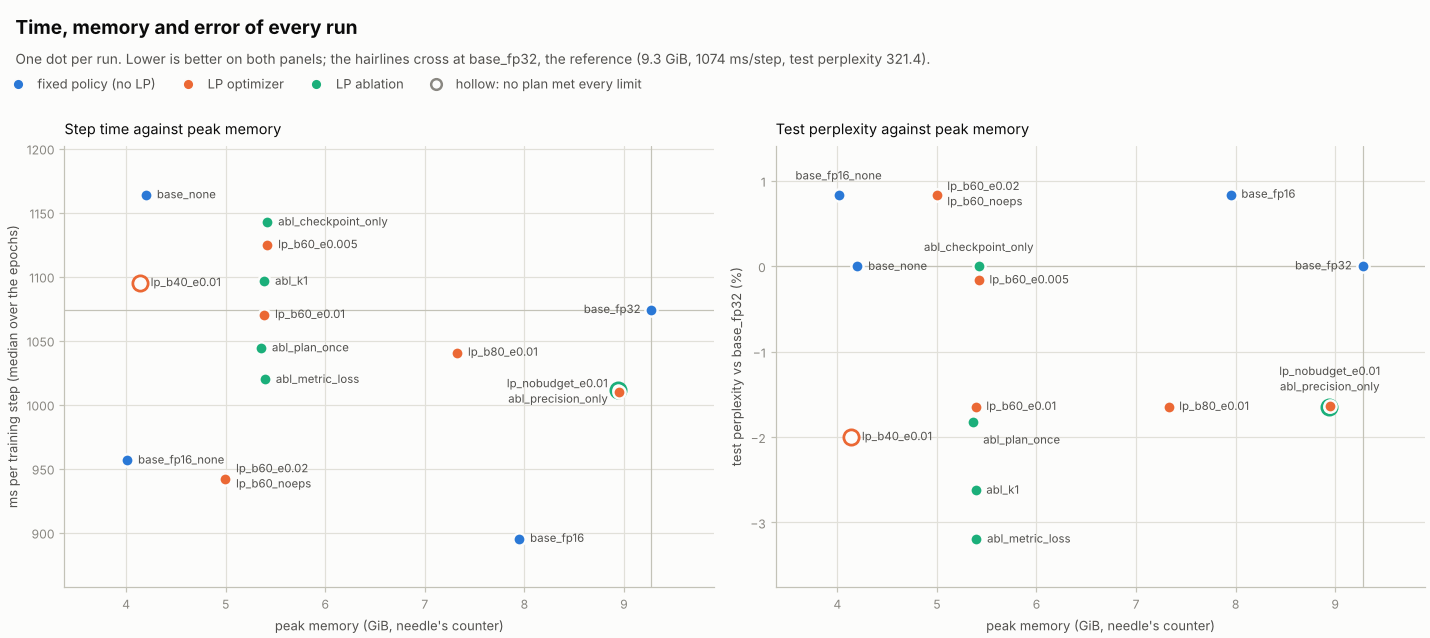

In [6]:
# The figures are drawn by plot.py from the same logs (into a temporary folder).
import tempfile
FIG = tempfile.mkdtemp()
subprocess.run([sys.executable, "plot.py", "stats/experiments", "--out", FIG, "--dpi", "110"], check=True,
               capture_output=True)
display(Image(f"{FIG}/tradeoff.png", width=1000))

**Figure 1. Time, memory and test perplexity of every run.** The hairlines cross at the float32 reference; hollow rings mark runs whose limits could not be met.

float16 everywhere is 1.20× faster but saves only 14% of the memory, since layer norm, softmax, the residual stream and the embedding and output layers stay in float32. Recomputation everywhere saves 55% for an 8% slowdown; both together save 57% and are still 1.12× faster. **At a 60% budget the planner beats either technique alone:** with ε = 0.01 it matches float32 speed (1,070 vs 1,074 ms per step) with 42% less memory, where recomputation alone (`abl_checkpoint_only`) needs 1,142 ms. With ε = 0.02 it is 1.14× faster than float32 with 46% less memory. Every run ends within 0.2% of the float32 training loss. Test perplexity varies between −3.2% and +0.8% with no pattern tied to the amount of float16; with one seed per run we read this as run-to-run variation.

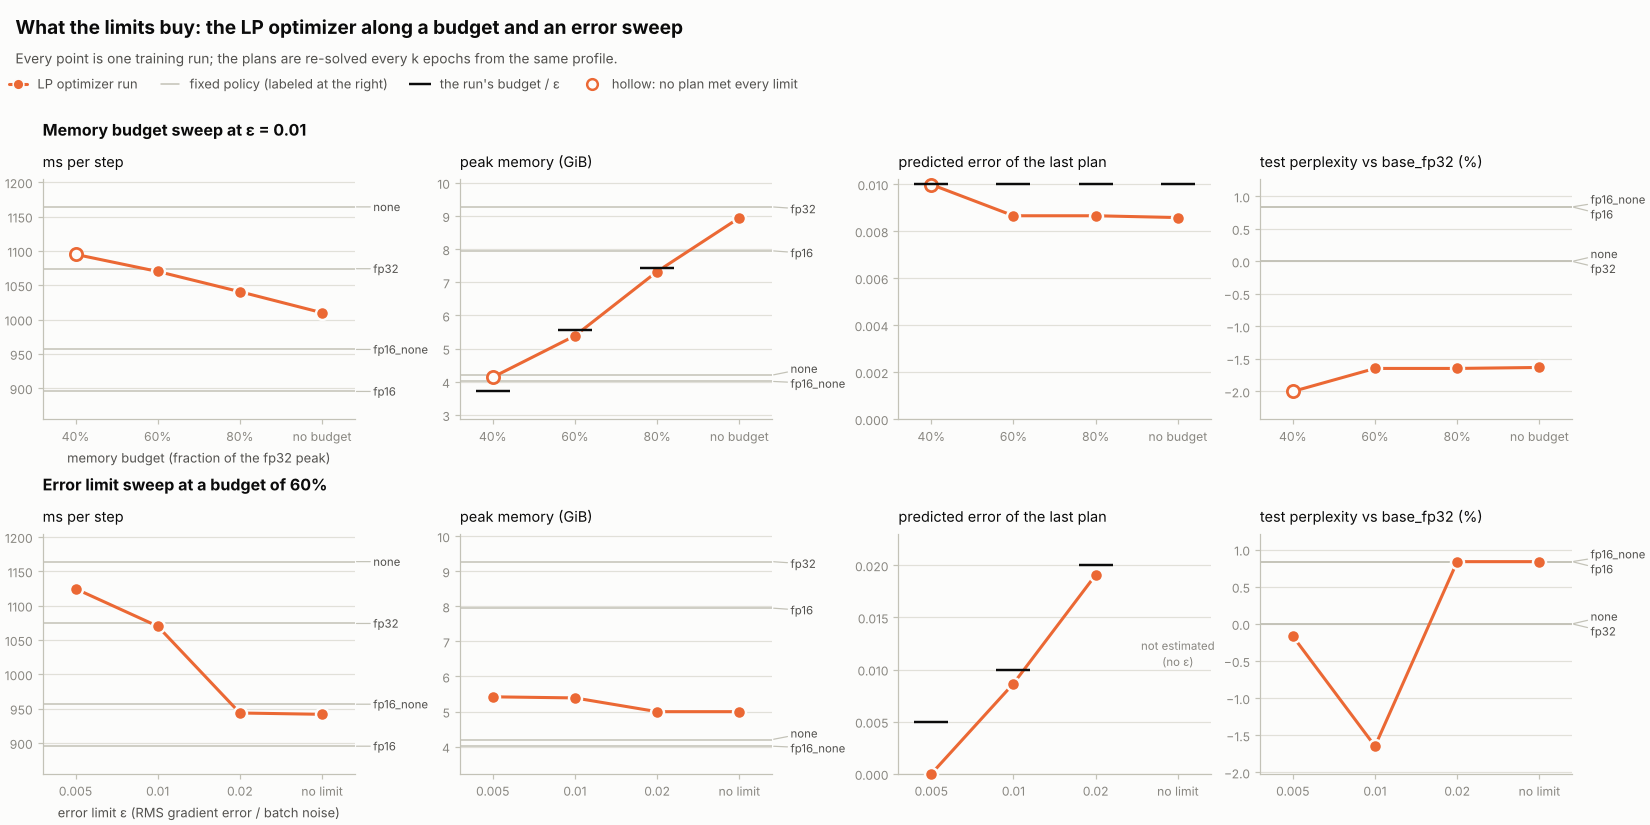

In [7]:
display(Image(f"{FIG}/sweeps.png", width=1000))

**Figure 2. Budget sweep (top) and error sweep (bottom).** Black marks are each run's budget or ε; gray lines are the fixed policies.

A looser budget buys speed until memory stops binding, and every feasible run stays under its budget. The 40% budget is infeasible: even `fp16_none` everywhere needs 43%. The planner reports this and uses the lowest-peak configuration within ε (4.1 GiB). At ε = 0.005 every layer ends up with float32 numerics and the run is 5% slower than the reference. ε = 0.02 already allows the same plan as no limit at all.

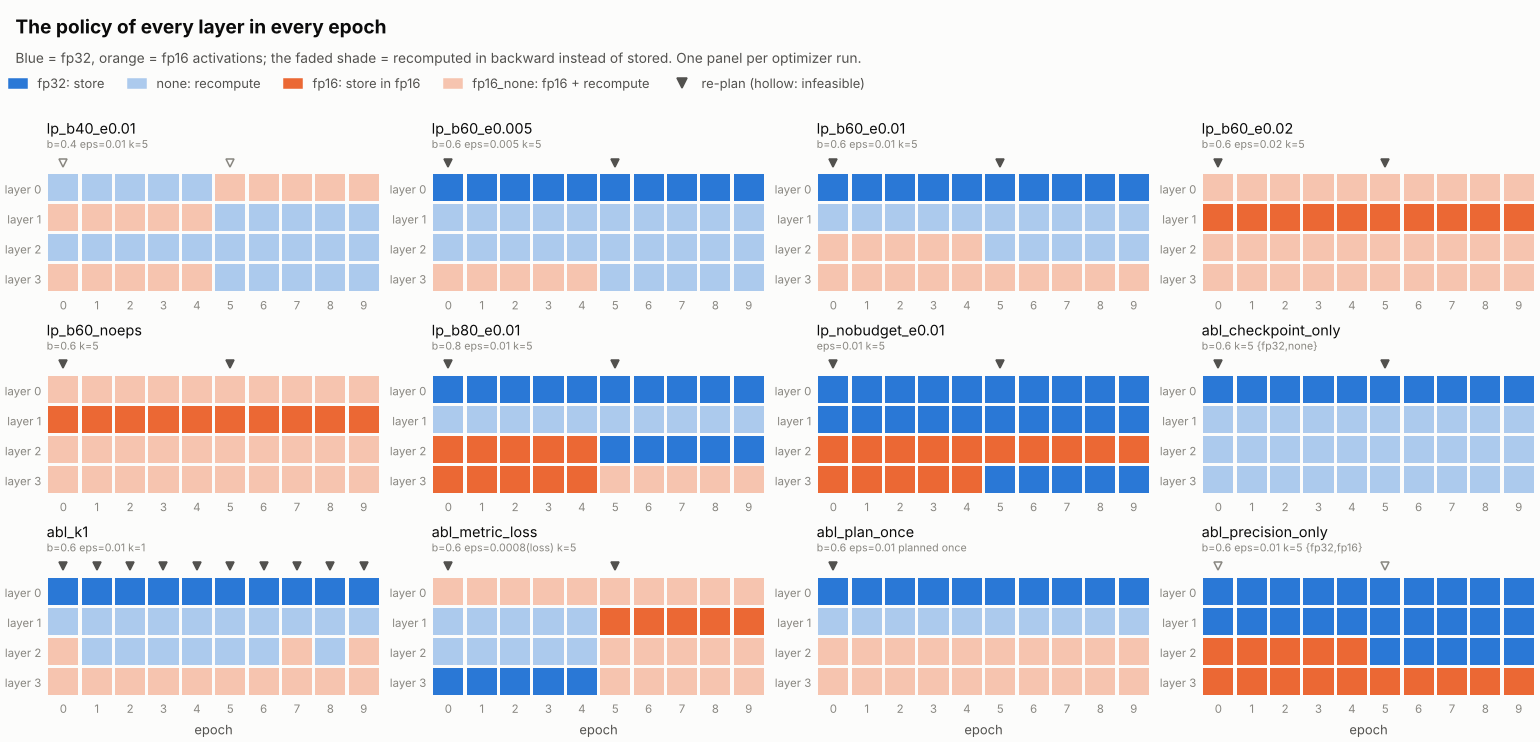

In [8]:
display(Image(f"{FIG}/plans.png", width=1000))

**Figure 3. The policy of every layer in every epoch.** Blue is float32, orange float16, faded shades are recomputed; triangles mark re-plans.

**Plans tighten as training converges.** The batch noise falls about tenfold in the first epoch, while the layers' float16 errors fall less. Measured against the noise, the same rounding therefore uses more of the error budget, and at the epoch-5 re-plan every run with ε = 0.01 moves one layer from float16 back to float32 numerics. In the feasible runs the first layer, whose float16 error alone is about ε, never leaves float32. Re-planning every epoch mostly repeats the epoch-1 plan, and planning only once is about 2.5% faster at the same final loss. Over 10 epochs, then, re-planning made training more conservative rather than measurably more accurate.

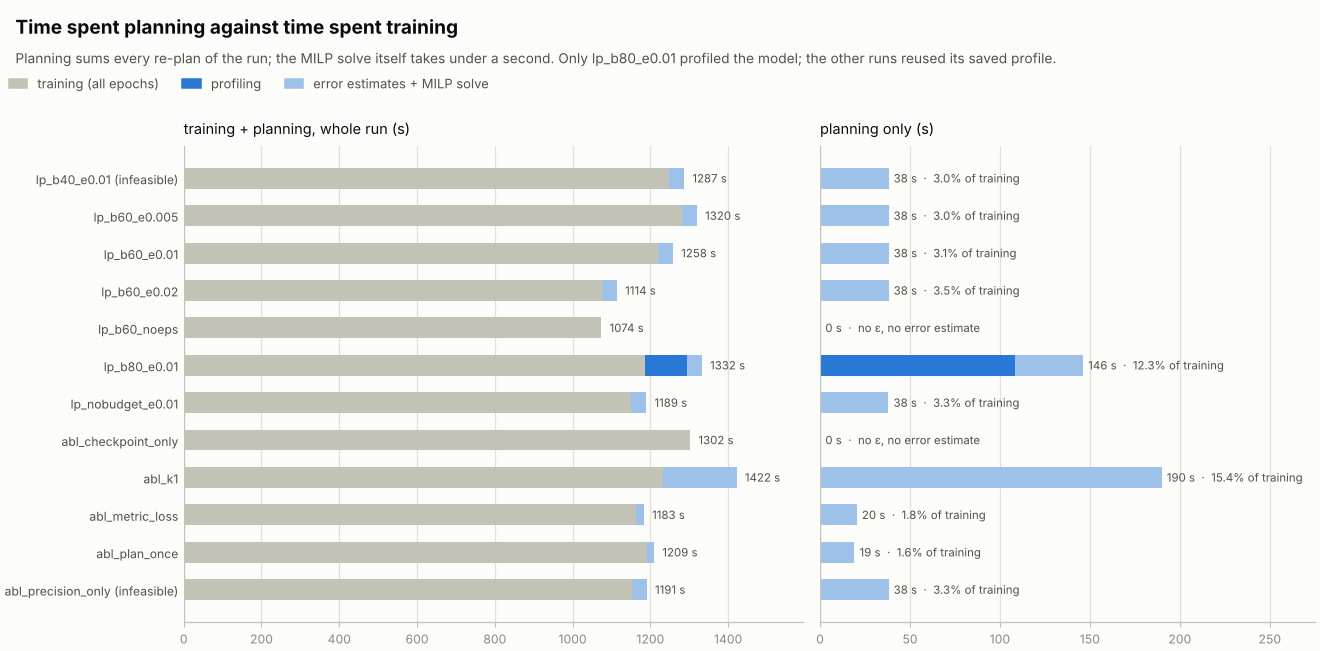

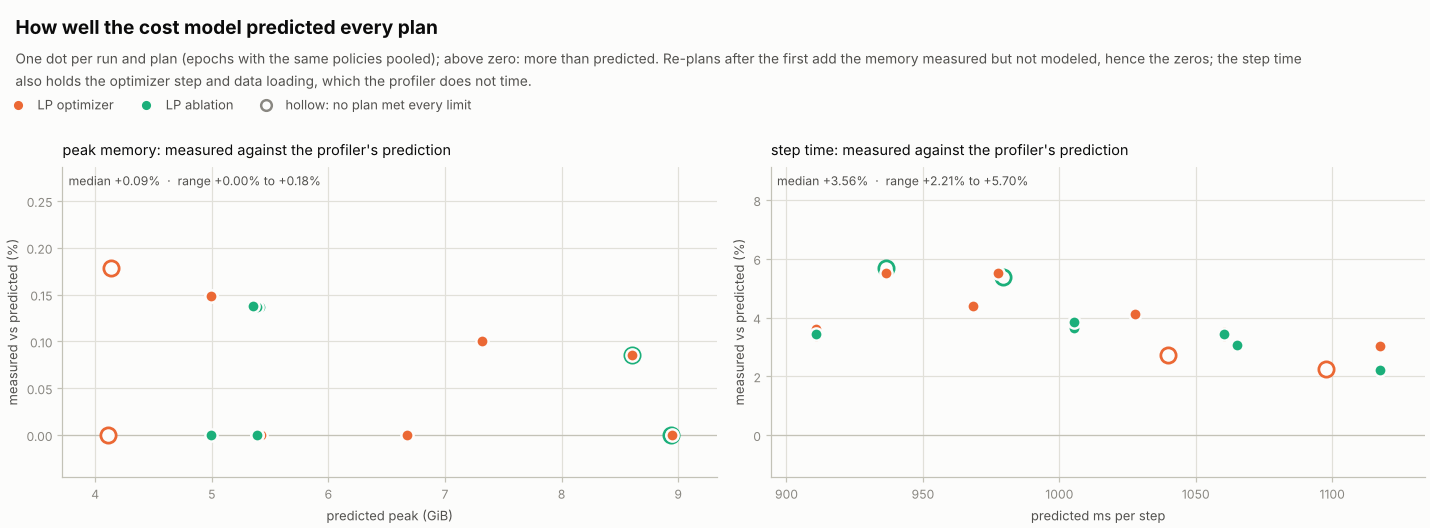

In [9]:
display(Image(f"{FIG}/planning.png", width=900))
display(Image(f"{FIG}/model.png", width=1000))

**Figure 4. Planning overhead (top) and accuracy of the cost model (bottom).**

Each re-plan spends about 19 s estimating errors and under a second solving the MILP, so re-planning every 5 epochs costs about 3% of the training time, and every epoch 15%. Profiling took 108 s once and was shared through a saved profile. Predicted peaks are within 0.2% of the measured ones, and exact after the controller adds the memory the profile cannot see. Measured step times are 2–6% above the predictions because they include the optimizer step and data loading, which affect every policy equally.

## 5. Limitations and future work

- **Memory is needle's counter.** It counts live `NDArray` buffers. What the GPU itself reports (`cudaMemGetInfo`) also includes the CUDA context, allocator caching and fragmentation; we have not yet compared the two.
- **A fixed cost dilutes the speed-ups.** The embedding and the loss build one-hot rows with `np.eye(vocabulary)` on the host, about 360 ms of every step for every policy. Gather-based kernels would remove it and enlarge every relative speed-up.
- **Gradients live until backward ends.** About 40% of the memory at the peak is intermediate gradients; freeing them early cut the float32 peak from 9.2 to 5.3 GB in a prototype. The planner would adapt through its profile.
- **Granularity and error model.** Four layers with four policies give only 256 configurations. The MILP scales linearly with layers and policies, so deeper models and finer segments (attention and MLP separately, as in [6]) are natural next steps. The error estimate is first order, assumes uncorrelated layers and estimates the noise from 8 batches, and with one seed per run, perplexity differences below about 3% are not significant.

## 6. Conclusion

We turned two global switches, mixed precision and gradient checkpointing, into a per-layer choice made by a planner from measured costs. The key pieces are float16 storage in needle's backends, checkpointing that replays the recorded graph with float32 segment boundaries, exact time and peak memory models, and an error metric relative to the gradient noise that gives ε a scale-free meaning. Within a memory budget, the planner was never slower than recomputation alone and often faster, it respected its limits, and its predictions were within a few percent of the measurements.

## 7. Code

The code is in the archive linked at the top. The link is private because the archive contains our needle homework solutions. Its layout:

| Path | Contents |
|---|---|
| `src/ndarray_backend_cpu.cc`, `src/ndarray_backend_cuda.cu` | C++ and CUDA kernels for float32, float16 and bfloat16 storage; the tensor-core matrix multiplication |
| `python/needle/backend_ndarray/ndarray.py` | `NDArray` with dtypes; the memory counter |
| `python/needle/autograd.py` | `Cast`, the autocast casting rules, `checkpoint()`, recomputation of released tensors, `no_grad`, backward hooks |
| `python/needle/amp.py` | `autocast` and `GradScaler` |
| `python/needle/nn/nn_transformer.py` | `Transformer` with per-layer policies, `run_segment`, the fused softmax |
| `python/needle/policy/profiler.py` | `profile_segments`, `SegmentProfile`: the time and memory cost tables |
| `python/needle/policy/error.py` | `estimate_segment_errors`, `SegmentErrors`: the precision error relative to the batch noise |
| `python/needle/policy/solver.py` | `solve`, `Plan`, `memory_frontier`, `error_frontier`: the MILP |
| `python/needle/policy/controller.py` | `PolicyController`: re-planning during training, the JSON log |
| `apps/profile_segments.py`, `apps/estimate_errors.py`, `apps/plan_policies.py` | command-line tools for each stage |
| `apps/train_policies.py` | training with the controller or with fixed policies |
| `train.sh`, `apps/summarize_runs.py`, `plot.py` | the runs of Section 4, the table and the figures |
| `stats/experiments/` | the logs of every run in Section 4 and the shared GPU profile |
| `tests/` | 1,150 tests (`unit`, `fp16test`, `bf16test`, `checkpoint`, `profiler`, `amp_error`, `solver`, `controller`, `experiments`, and others); the GPU tests are skipped without a GPU |
| `human-docs/` | the planner's user guide and the design decisions |

To reproduce the experiments on a GPU, with the Penn Treebank data in `data/ptb`:

```bash
./train.sh all     # the 16 runs of Section 4 (about 4 hours), then the summary table
./train.sh plot    # the figures, in stats/experiments/plots
```

The cell below runs the tests for checkpointing, the policies, the error estimate and the solver (about one minute on a CPU); `python -m pytest tests` runs the full suite.

In [10]:
result = subprocess.run([sys.executable, "-m", "pytest", "tests/checkpoint", "tests/policy", "tests/solver",
                         "tests/amp_error", "-q", "--color=no", "-p", "no:cacheprovider"], capture_output=True, text=True)
print(result.stdout.splitlines()[-1])

165 passed, 51 skipped in 42.45s


## References

1. P. Micikevicius, S. Narang, J. Alben, et al. *Mixed Precision Training.* ICLR 2018.
2. D. Kalamkar, D. Mudigere, N. Mellempudi, et al. *A Study of BFLOAT16 for Deep Learning Training.* arXiv:1905.12322, 2019.
3. A. Paszke, S. Gross, F. Massa, et al. *PyTorch: An Imperative Style, High-Performance Deep Learning Library.* NeurIPS 2019; documentation of `torch.amp` and `torch.utils.checkpoint`.
4. A. Griewank and A. Walther. *Algorithm 799: Revolve: An Implementation of Checkpointing for the Reverse or Adjoint Mode of Computational Differentiation.* ACM Transactions on Mathematical Software 26(1), 2000.
5. T. Chen, B. Xu, C. Zhang, and C. Guestrin. *Training Deep Nets with Sublinear Memory Cost.* arXiv:1604.06174, 2016.
6. V. Korthikanti, J. Casper, S. Lym, et al. *Reducing Activation Recomputation in Large Transformer Models.* MLSys 2023.
7. P. Jain, A. Jain, A. Nrusimha, et al. *Checkmate: Breaking the Memory Wall with Optimal Tensor Rematerialization.* MLSys 2020.
8. A. Shah, C.-Y. Wu, J. Mohan, V. Chidambaram, and P. Krähenbühl. *Memory Optimization for Deep Networks.* ICLR 2021.
9. M. Kirisame, S. Lyubomirsky, A. Haan, et al. *Dynamic Tensor Rematerialization.* ICLR 2021.
10. X. Peng, X. Shi, H. Dai, et al. *Capuchin: Tensor-based GPU Memory Management for Deep Learning.* ASPLOS 2020.
11. J. Chen, L. Zheng, Z. Yao, et al. *ActNN: Reducing Training Memory Footprint via 2-Bit Activation Compressed Training.* ICML 2021.
12. S. McCandlish, J. Kaplan, D. Amodei, and the OpenAI Dota Team. *An Empirical Model of Large-Batch Training.* arXiv:1812.06162, 2018.
13. Q. Huangfu and J. A. J. Hall. *Parallelizing the Dual Revised Simplex Method.* Mathematical Programming Computation 10, 2018.
14. P. Virtanen, R. Gommers, T. E. Oliphant, et al. *SciPy 1.0: Fundamental Algorithms for Scientific Computing in Python.* Nature Methods 17, 2020.
15. T. Chen and Z. Kolter. *Deep Learning Systems: Algorithms and Implementation* (10-414/714) and its needle library. Carnegie Mellon University.